## Question:
### in soccer If a goalie stops 30% of penalty kicks so whats is the probability they make at least 2 saves in 5 attempts at the goal?

## simulation:
### im simulatiing 2 shots or more one trial blocking the soccer ball. The outcomes are either the ball making it in or not making it in . 

## Analysis:

In [2]:
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for the graph
sns.set_theme(style="whitegrid")

In [3]:
# Parameters: 5 penalty kicks per trial, 30% save probability (0.30)
num_trials = 5000
save_prob = 0.30
saves_results = []

for _ in range(num_trials):
    # Simulate 5 penalty kicks (True = Goal saved, False = Goal scored)
    # Using random.random() to simulate the 30% chance
    saves = sum(1 for _ in range(5) if random.random() < save_prob)
    saves_results.append(saves)

# Store results in a Pandas DataFrame
df = pd.DataFrame({'Saves': saves_results})
print(df['Saves'].value_counts().sort_index())

Saves
0     825
1    1814
2    1584
3     641
4     118
5      18
Name: count, dtype: int64


In [4]:
# Calculate the mean and standard deviation of the simulated saves
mean_saves = df['Saves'].mean()
std_saves = df['Saves'].std()

print(f"Mean saves per 5 kicks: {mean_saves:.2f}")
print(f"Standard deviation: {std_saves:.2f}")

Mean saves per 5 kicks: 1.49
Standard deviation: 1.01


In [5]:
# Calculate the percentage of trials where the goalie made at least 2 saves
at_least_2_prob = (df['Saves'] >= 2).mean()

print(f"Simulated Probability of at least 2 saves: {at_least_2_prob * 100:.2f}%")

Simulated Probability of at least 2 saves: 47.22%


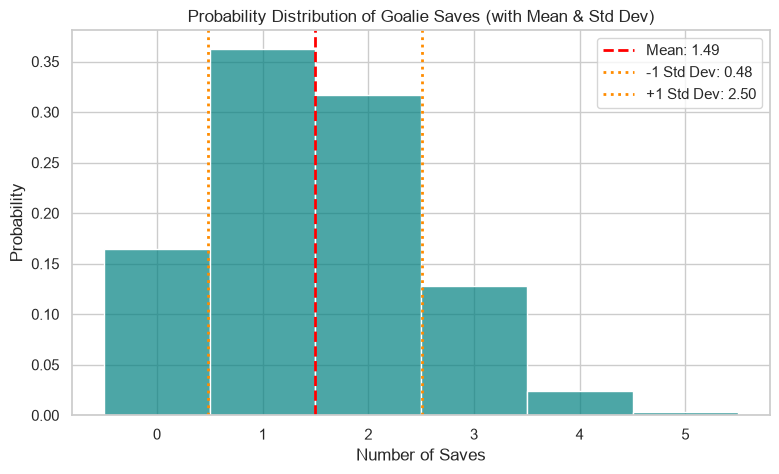

In [6]:
# Plot the probability distribution with Mean and Standard Deviation markers
plt.figure(figsize=(9, 5))
sns.histplot(df['Saves'], discrete=True, stat="probability", color="teal", alpha=0.7)

# Calculate theoretical/simulated statistics
mean_saves = df['Saves'].mean()
std_saves = df['Saves'].std()

# Add line for Mean
plt.axvline(mean_saves, color='red', linestyle='--', linewidth=2, 
            label=f'Mean: {mean_saves:.2f}')

# Add lines for +/- 1 Standard Deviation
plt.axvline(mean_saves - std_saves, color='darkorange', linestyle=':', linewidth=2, 
            label=f'-1 Std Dev: {mean_saves - std_saves:.2f}')
plt.axvline(mean_saves + std_saves, color='darkorange', linestyle=':', linewidth=2, 
            label=f'+1 Std Dev: {mean_saves + std_saves:.2f}')

plt.title('Probability Distribution of Goalie Saves (with Mean & Std Dev)')
plt.xlabel('Number of Saves')
plt.ylabel('Probability')
plt.legend()
plt.show()

In [7]:
# Calculate empirical probability of at least 2 saves from the simulated data
empirical_prob = (df['Saves'] >= 2).mean()

print(f"Empirical Probability (X >= 2): {empirical_prob:.4f} ({empirical_prob * 100:.2f}%)")

Empirical Probability (X >= 2): 0.4722 (47.22%)


In [9]:
from scipy.stats import binom

# Parameters: n = 5 kicks, p = 0.30 save probability
n = 5
p = 0.30

# Calculate theoretical probability P(X >= 2) using 1 - P(X <= 1)
theoretical_prob = 1 - binom.cdf(1, n, p)

print(f"Theoretical Probability (X >= 2): {theoretical_prob:.4f} ({theoretical_prob * 100:.2f}%)")

Theoretical Probability (X >= 2): 0.4718 (47.18%)


In [10]:
import math

# Parameters: n = 5 kicks, p = 0.30 save probability
n = 5
p = 0.30

# Theoretical Standard Deviation: sqrt(n * p * (1 - p))
theoretical_std = math.sqrt(n * p * (1 - p))

print(f"Theoretical Standard Deviation: {theoretical_std:.4f}")

Theoretical Standard Deviation: 1.0247


In [11]:
from scipy.stats import binom

# Calculate theoretical standard deviation directly from SciPy distribution
theoretical_std_scipy = binom.std(n=5, p=0.30)

print(f"Theoretical Standard Deviation (SciPy): {theoretical_std_scipy:.4f}")

Theoretical Standard Deviation (SciPy): 1.0247


## Conclusion:

 ###      So in professional soccer one thing the always impact a game is a penalty shootout so we're testing if a goalie with a 30% of blocking a shot could block atleast 2 shots while in a five penalty shootcut. our theoretical guess was 47.18% for it to be possible to block atleast 2 shots but our empirical probablity which is from our data is 47.22% and is better then our theortical guess showing within our 5000 simulations it turns out blocking atleast 2 shots the probality is greater then the guess. even our emprirical mean and standard deivation is close to our theoretical versions. like look at this our theoretical version of mean is 1.5 but in the empirical its 1.49 this is great proving both of this more correct. standard deviation is 1.03 for theoretical but its 1.01 for our emprical these are similar proving both of them correct. what mean and deviation mean in this context is that we can expect the goalie to make 1.49 shots using our simulation data but it can varie by 1.01 so either not able to block anything to able to block three shots. Even our graph above suppports this conclusion as using this data it applys the standard deviation proving that .48 isn't really blocking a shot but 2.5 is definely three shots it brings data more better and easier to understand.